# 3 · Proliferation with small diffusion — corrected

Corrected version of [`original/notebooks/03-proliferation-small-diffusion.ipynb`](../../original/notebooks/03-proliferation-small-diffusion.ipynb). The original is kept unchanged.

**Model** — Fisher–Kolmogorov equation (diffusion + logistic growth):

$$\frac{\partial n}{\partial t} = D\,\nabla^2 n + \alpha_0\, n\left(1 - \frac{n}{N_{\max}}\right)$$

**What changed from the original**

- **Growth term was multiplied by D.** The original update was `delta_t * ((D1 / delta_x**2) * (laplacian + Alpha_zero*n*(1 - n/N_Max)))`: the growth term sat *inside* the diffusion bracket. The effective growth rate was therefore $\alpha_0 D_1 = 0.002$ instead of $\alpha_0 = 2$, i.e. 1000× too slow. That is why the original's peak density only rose from 0.10 to 0.14 in 2000 steps. With the stated equation the tumour reaches $N_{\max} = 1$ within about 100 steps.
- **Initial cutoff** (see the comment in the initial-condition cell).
- Removed the unused `D = 2`; NumPy array operations instead of nested loops.

> **Caveat — grid resolution.** The width of the tumour edge is about $\sqrt{D/\alpha_0} \approx 0.02$ grid cells, far thinner than one cell. At that resolution how fast the tumour spreads is set mostly by the grid, not by $D$. Parameters are kept as in the original for comparison; for quantitative work use $\Delta x$ well below $\sqrt{D/\alpha_0}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Parameters (same as the original; D1 renamed to D)
l = 200
A = 0.05
σ1, σ2, σ3 = 15, 25, 12
delta_t = 0.1
delta_x = 1
D = 0.001         # small diffusion
Alpha_zero = 2    # proliferation rate
N_Max = 1         # carrying capacity
cutoff = 1e-3     # densities below this count as "no tumour" (new)
num_steps = 2000
save_steps = [100, 480, 860, 1240, 1620, 2000]

# The explicit scheme is only stable if D*dt/dx^2 <= 0.25 (2D, 5-point stencil)
assert D * delta_t / delta_x**2 <= 0.25, "unstable: reduce delta_t"

In [3]:
def laplacian(n):
    """5-point Laplacian. np.roll wraps around the edges, giving the same
    periodic boundaries as the original notebook."""
    return (np.roll(n, 1, axis=0) + np.roll(n, -1, axis=0)
            + np.roll(n, 1, axis=1) + np.roll(n, -1, axis=1) - 4 * n) / delta_x**2

In [4]:
# Same three Gaussian regions as the original notebook
i, j = np.meshgrid(np.arange(l), np.arange(l), indexing="ij")

def gaussian(ci, cj, sigma):
    return A * np.exp(-((i - ci)**2 + (j - cj)**2) / (2 * sigma**2))

n = gaussian(l/2, l/2 - 10, σ1) + gaussian(l/2, 3*l/4 - 30, σ2) + gaussian(2*l/5, 3*l/5 - 10, σ3)

# A Gaussian is never exactly zero. With logistic growth, even its 1e-30 tails
# grow exponentially and the whole grid fills up "spontaneously" within a few
# hundred steps. Treat densities below the cutoff as "no tumour cells".
n[n < cutoff] = 0.0

In [5]:
frames = {0: n.copy()}
for step in range(1, num_steps + 1):
    n = n + delta_t * (D * laplacian(n) + Alpha_zero * n * (1 - n / N_Max))
    if step in save_steps:
        frames[step] = n.copy()
        print(f"step {step:5d}: max density {n.max():.3f}")

step   100: max density 1.000
step   480: max density 1.000


step   860: max density 1.000
step  1240: max density 1.000


step  1620: max density 1.000
step  2000: max density 1.000


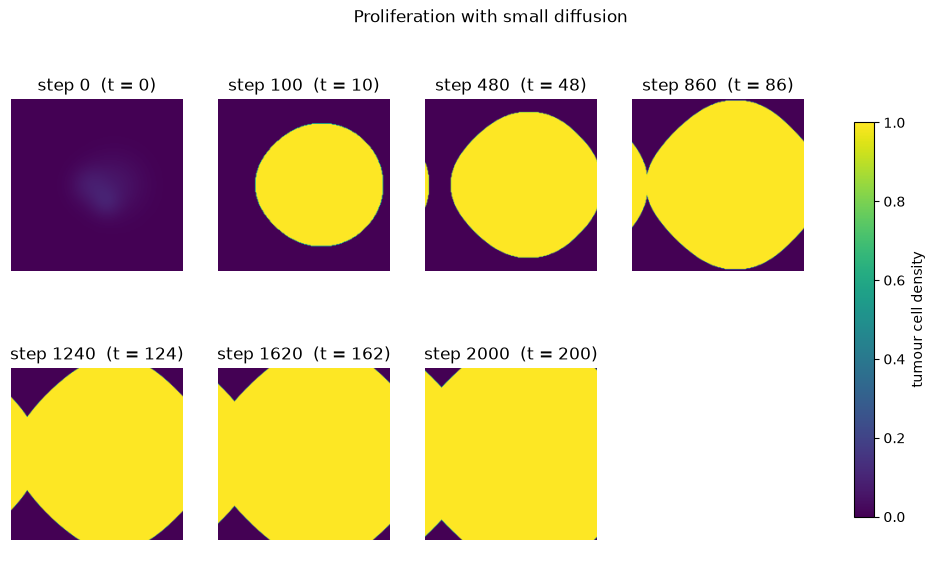

In [6]:
fig, axes = plt.subplots(int(np.ceil(len(frames) / 4)), 4, figsize=(3.2 * 4, 3.2 * int(np.ceil(len(frames) / 4))), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, (step, frame) in zip(axes.flat, frames.items()):
    im = ax.imshow(frame, origin="lower", cmap="viridis", vmin=0, vmax=N_Max)
    ax.set_title(f"step {step}  (t = {step * delta_t:g})")
fig.colorbar(im, ax=axes, shrink=0.8, label="tumour cell density")
fig.suptitle("Proliferation with small diffusion")
plt.show()

**Reading the result.** The regions fill up to the carrying capacity almost immediately, then the tumour keeps expanding slowly at its edge. Because the boundaries are periodic, a tumour that reaches one edge reappears on the opposite edge.